# ✿ Iris Intelligence
## An inspectable journey from measurements to classification
Explore the data. Understand the model. Predict the species.

This executed notebook uses the authentic required [Kaggle CSV](https://www.kaggle.com/datasets/saurabh00007/iriscsv). It reuses the project's modular implementation and writes its independent demonstration experiment to a temporary directory.

## 1 · Problem and dataset
Supervised multiclass classification predicts setosa, versicolor or virginica from sepal/petal length and width in cm. Id is an identifier, never a feature. We do not classify photographs.

In [1]:
from pathlib import Path
import sys, tempfile
root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root))
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown
from src.config import FEATURES, LABELS, COLORS, NAMES, DATA_PATH
from src.data_loader import load_data, inspection, extract_features
from src.preprocessing import split_data, measurement_groups
from src.train import train
from src.predict import load_bundle, predict
from src.utils import read_json, sha256
from src.eda import export_figures
%matplotlib inline
print('Python:', sys.version.split()[0])

Python: 3.11.9


## 2 · Load and validate
The loader rejects missing/unknown fields, invalid cm values, conflicting labels and invalid IDs. It retains legitimate repeated observations. Provenance is checked against the exact CSV bytes.

In [2]:
frame = load_data()
provenance = read_json(DATA_PATH.with_suffix('.provenance.json'))
assert provenance['sha256'] == sha256(DATA_PATH)
display(pd.Series(provenance, name='Acquisition provenance'))
display(frame.head())
audit = inspection(frame)
display(pd.Series({k: audit[k] for k in ['rows','duplicate_full_rows','duplicate_measurement_rows','class_counts','cleaning']}))
display(frame[FEATURES].describe())

source           https://www.kaggle.com/datasets/saurabh00007/i...
method           direct HTTPS download from official Kaggle dat...
retrieved_utc                     2026-10-19T14:56:46.253065+00:00
sha256           600ac44f23c2e6e0ae37daac8ceb2baba4df963efa580e...
filename                                                  Iris.csv
rows                                                           150
Name: Acquisition provenance, dtype: object

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


rows                                                                        150
duplicate_full_rows                                                           0
duplicate_measurement_rows                                                    3
class_counts                  {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Ir...
cleaning                      Numeric types validated; Id excluded from feat...
dtype: object

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3 · Exploratory analysis
These plots are descriptive. Visually separated clusters do not validate future performance. Petal features distinguish setosa well in this sample; versicolor and virginica show more overlap.

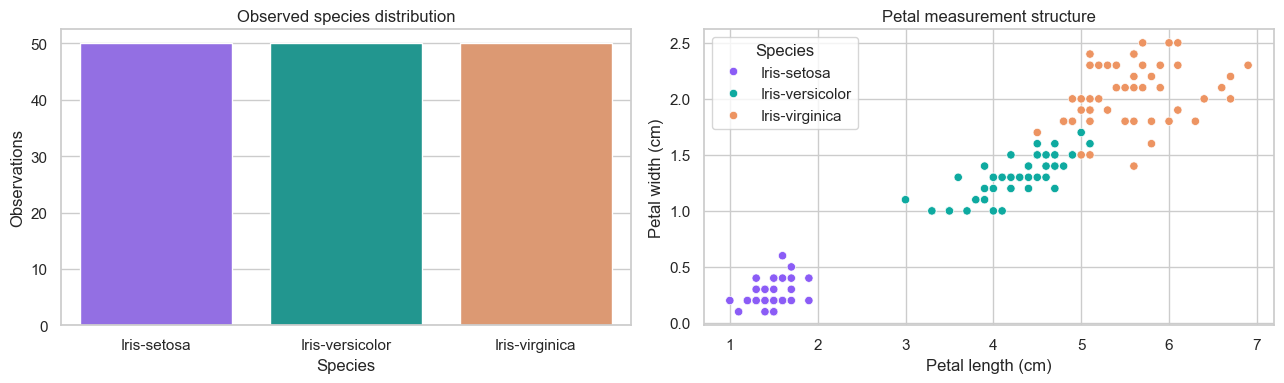

SepalLengthCm                  SepalWidthCm                   \
                         mean    std  min  max         mean    std  min  max   
Species                                                                        
Iris-setosa             5.006  0.352  4.3  5.8        3.418  0.381  2.3  4.4   
Iris-versicolor         5.936  0.516  4.9  7.0        2.770  0.314  2.0  3.4   
Iris-virginica          6.588  0.636  4.9  7.9        2.974  0.322  2.2  3.8   

                PetalLengthCm                  PetalWidthCm                   
                         mean    std  min  max         mean    std  min  max  
Species                                                                       
Iris-setosa             1.464  0.174  1.0  1.9        0.244  0.107  0.1  0.6  
Iris-versicolor         4.260  0.470  3.0  5.1        1.326  0.198  1.0  1.8  
Iris-virginica          5.552  0.552  4.5  6.9        2.026  0.275  1.4  2.5

In [3]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=frame, x='Species', hue='Species', palette=COLORS, legend=False, ax=axes[0])
axes[0].set(title='Observed species distribution', ylabel='Observations')
sns.scatterplot(data=frame, x=FEATURES[2], y=FEATURES[3], hue='Species', palette=COLORS, ax=axes[1])
axes[1].set(title='Petal measurement structure', xlabel=NAMES[FEATURES[2]], ylabel=NAMES[FEATURES[3]])
plt.tight_layout(); plt.show()
display(frame.groupby('Species')[FEATURES].agg(['mean','std','min','max']).round(3))

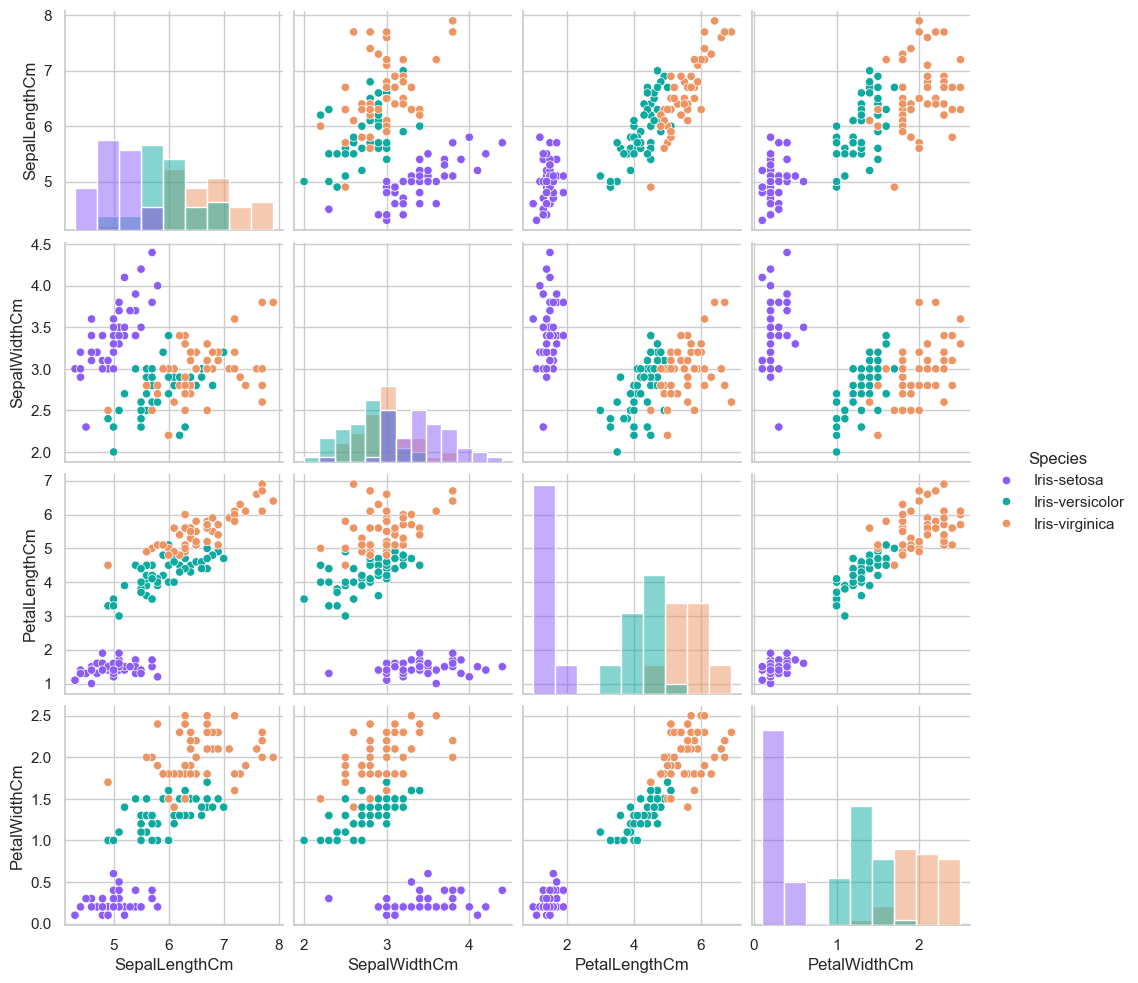

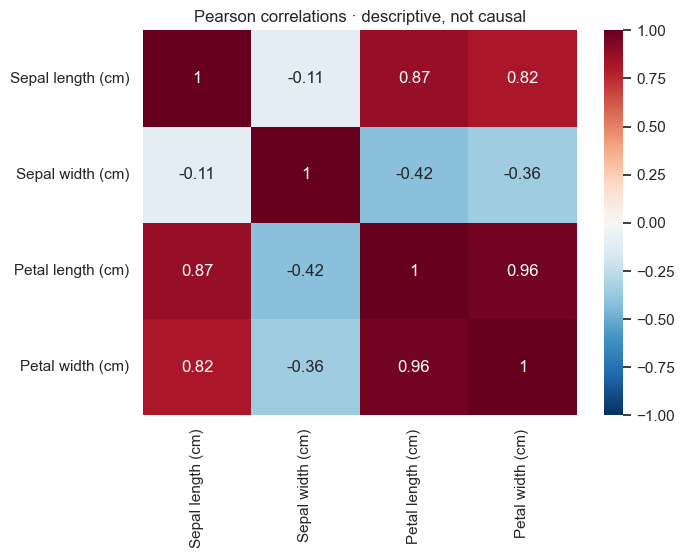

In [4]:
grid = sns.pairplot(frame, vars=FEATURES, hue='Species', palette=COLORS, diag_kind='hist')
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(frame[FEATURES].rename(columns=NAMES).corr(), annot=True, vmin=-1, vmax=1, cmap='RdBu_r', ax=ax)
ax.set_title('Pearson correlations · descriptive, not causal'); plt.show()

## 4 · Features and the untouched holdout
Group identical four-feature tuples, then stratify unique groups using an 80/20 split and seed 42. This keeps repeated measurements together and preserves every observation. Row ratios can differ from group ratios. Do not fit preprocessing on the complete dataset.

In [5]:
X, y = extract_features(frame)
training, testing = split_data(frame)
groups = measurement_groups(frame)
assert set(groups.loc[training]).isdisjoint(groups.loc[testing])
print(f'{len(training)} training rows; {len(testing)} held-out rows')
print('Features:', list(X.columns))
print('Train labels:', y.loc[training].value_counts().to_dict())

120 training rows; 30 held-out rows
Features: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Train labels: {'Iris-setosa': 40, 'Iris-versicolor': 40, 'Iris-virginica': 40}


## 5 · Training, grouped CV and hyperparameter tuning
The reused training function constructs all five pipelines. Logistic regression, KNN and SVM scale within CV; trees use passthrough. Five-fold shuffled stratified group CV tunes only training rows. Macro F1 chooses the winner; exact ties use accuracy and a fixed simplicity order. Scores after tuning are selection estimates and may be optimistic. The untouched test set is evaluated only after selection.

In [6]:
temporary = tempfile.TemporaryDirectory(prefix='iris-notebook-')
experiment_dir = Path(temporary.name)
experiment = train(DATA_PATH, output=experiment_dir)
meta, metrics = experiment['metadata'], experiment['metrics']
comparison = pd.DataFrame(experiment['comparison'])
display(comparison[['model','cv_macro_f1','cv_std','cv_accuracy','best_params']])
print('Selected:', meta['selected_model'])
print(meta['selection'])

Logistic Regression: CV macro F1=0.96633


K-Nearest Neighbors: CV macro F1=0.95790


Support Vector Machine: CV macro F1=0.96633


Decision Tree: CV macro F1=0.96654


Random Forest: CV macro F1=0.96633


,model,cv_macro_f1,cv_std,cv_accuracy,best_params
0,Logistic Regression,0.966330,0.031276,0.965152,{'model__C': 10}
1,K-Nearest Neighbors,0.957899,0.045826,0.956061,"{'model__n_neighbors': 7, 'model__p': 1, 'mode..."
2,Support Vector Machine,0.966330,0.031276,0.965152,"{'model__C': 1, 'model__kernel': 'linear'}"
3,Decision Tree,0.966536,0.048782,0.964394,"{'model__max_depth': 3, 'model__min_samples_le..."
4,Random Forest,0.966330,0.031276,0.965152,"{'model__max_depth': None, 'model__min_samples..."


Selected: Decision Tree
Highest training CV macro F1; numerical ties resolved by CV accuracy then fixed simplicity order (linear, neighbors, SVM, tree, forest). Holdout never used for selection.


## 6 · Model comparison
Error bars describe variability among training folds, not confidence intervals. The tiny score differences do not establish general model superiority.

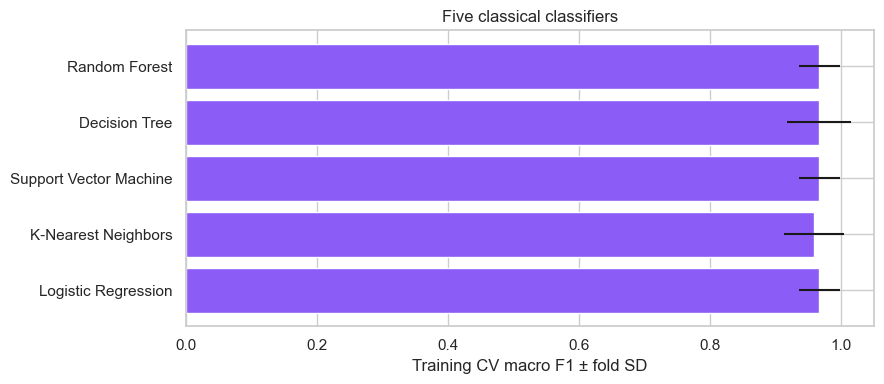

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(comparison.model, comparison.cv_macro_f1, xerr=comparison.cv_std, color='#8b5cf6')
ax.set(xlim=(0,1.05), xlabel='Training CV macro F1 ± fold SD', title='Five classical classifiers')
plt.tight_layout(); plt.show()

## 7 · Independent final evaluation
Accuracy is the fraction correct. Macro F1 gives every class equal weight. Weighted F1 uses class support. The confusion matrix shows actual labels by row and predictions by column. The saved model remains fitted on training rows only.

accuracy               0.966667
macro_precision        0.969697
macro_recall           0.966667
macro_f1               0.966583
weighted_precision     0.969697
weighted_recall        0.966667
weighted_f1            0.966583
correct               29.000000
incorrect              1.000000
test_rows             30.000000
Name: Holdout metrics, dtype: float64

,precision,recall,f1-score,support
Iris-setosa,1.000000,1.000000,1.000000,10.000000
Iris-versicolor,1.000000,0.900000,0.947368,10.000000
Iris-virginica,0.909091,1.000000,0.952381,10.000000
accuracy,0.966667,0.966667,0.966667,0.966667
macro avg,0.969697,0.966667,0.966583,30.000000
weighted avg,0.969697,0.966667,0.966583,30.000000


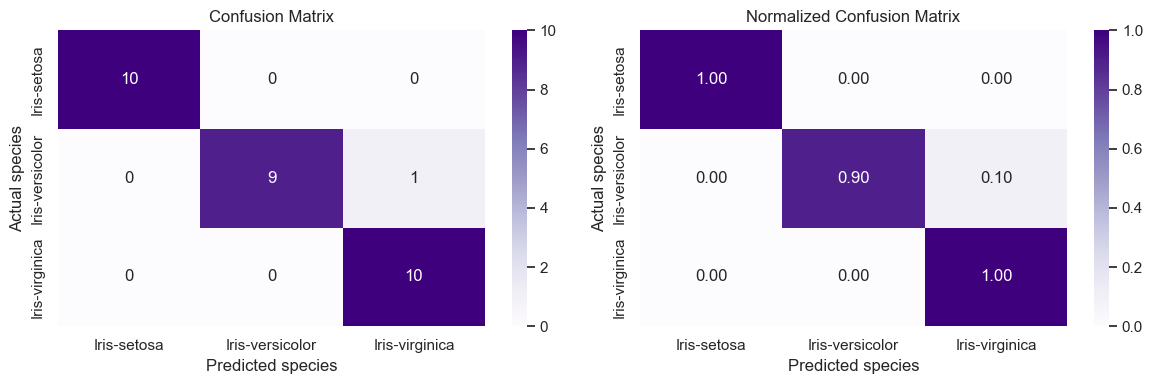

In [8]:
display(pd.Series({k:v for k,v in metrics.items() if not isinstance(v, (dict,list))}, name='Holdout metrics'))
display(pd.DataFrame(metrics['classification_report']).T)
fig, axes = plt.subplots(1,2, figsize=(12,4))
for ax, key, fmt in zip(axes, ['confusion_matrix','normalized_confusion_matrix'], ['d','.2f']):
    sns.heatmap(pd.DataFrame(metrics[key], index=LABELS, columns=LABELS), annot=True, fmt=fmt, cmap='Purples', ax=ax)
    ax.set(title=key.replace('_',' ').title(), xlabel='Predicted species', ylabel='Actual species')
plt.tight_layout(); plt.show()

## 8 · Feature relevance and real mistakes
Holdout permutation importance is a post-selection global diagnostic, not a local or causal explanation. Correlated features can substitute for one another. Test errors below are actual errors; if empty, no error is invented.

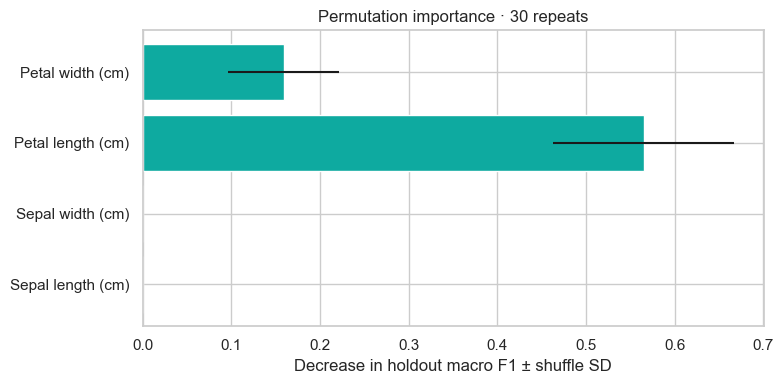

,row_index,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,actual,predicted,correct
0,77,6.7,3.0,5.0,1.7,Iris-versicolor,Iris-virginica,False


Actual mistakes on this split: 1


In [9]:
importance = pd.read_csv(experiment_dir/'reports/metrics/permutation_importance.csv')
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(importance.feature.map(NAMES), importance['mean'], xerr=importance['std'], color='#0eaaa0')
ax.set(xlabel='Decrease in holdout macro F1 ± shuffle SD', title='Permutation importance · 30 repeats')
plt.tight_layout(); plt.show()
errors = pd.read_csv(experiment_dir/'reports/metrics/errors.csv')
display(errors)
print(f'Actual mistakes on this split: {len(errors)}')

## 9 · Persistence and inference
Load only trusted local joblib files. Measurements are validated and ordered by name. Probability estimates are not guarantees. A sample from this dataset is a demonstration, not independent validation.

In [10]:
model, loaded_meta = load_bundle(experiment_dir/'models')
sample = frame.iloc[0][FEATURES].to_dict()
result = predict(model, loaded_meta, sample)
display(pd.Series(result))
assert set(result['probabilities']) == set(LABELS)
assert abs(sum(result['probabilities'].values())-1) < 1e-10
canonical = read_json(root/'reports/metrics/evaluation.json')
assert metrics['accuracy'] == canonical['accuracy']
assert abs(metrics['macro_f1']-canonical['macro_f1']) < 1e-12
print('Reproduced canonical holdout metrics exactly.')

species                                                         Iris-setosa
probabilities             {'Iris-setosa': 1.0, 'Iris-versicolor': 0.0, '...
measurements              {'SepalLengthCm': 5.1, 'SepalWidthCm': 3.5, 'P...
outside_training_range                                                   []
dtype: object

Reproduced canonical holdout metrics exactly.


## 10 · Discussion, limitations and conclusion
Petal measurements show clear descriptive structure for setosa, with more overlap between the other species. The selected model and genuine scores above document this specific seed-42 experiment. A balanced 150-flower historical benchmark is too small and narrow to prove broad botanical reliability. There is no independent probability-calibration study, and unfamiliar feature combinations can be risky even within individual feature ranges. Future work should add external observations, nested CV and measurement-noise studies.

The project demonstrates the full numerical classification lifecycle: provenance, validation, exploration, grouped splitting, leakage-safe pipelines, training-only selection, independent evaluation, error analysis and persisted inference.

### References
- [Required Kaggle dataset](https://www.kaggle.com/datasets/saurabh00007/iriscsv)
- [Scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
- [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)

In [11]:
temporary.cleanup()